# Task 2 - Qualification Classification

Experiments for Task 2, following the notebook workflow used by Tasks 1 and 3. Shared logic remains in `task2_cls/` so notebook and CLI use the same preprocessing, training, and evaluation.

**Protocol:** deduplicate before the saved stratified 80/10/10 split (seed 42); fit TF-IDF only on train; select C and the consistent candidate using validation; report test after selection. Level targets are weak labels from experience rules, not human seniority annotations.

## 1. Environment and run controls
Required inputs: `data/resume_atlas.parquet` and `outputs/ner/ner_atlas.parquet`. Keep the same inputs and split artifacts when comparing models.

In [ ]:
# Optional setup for a fresh notebook environment:
# %pip install pandas numpy pyarrow scikit-learn joblib threadpoolctl matplotlib

RUN_BASELINES = False
REBUILD_DATA = False
THREADS = 4

import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start = Path(os.environ.get("TASK2_REPO_ROOT", Path.cwd())).resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "task2_cls").is_dir() and (p / "TASKS.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project or set TASK2_REPO_ROOT.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from task2_cls.data import prepare_assets, split_frames
from task2_cls.baselines import load_model, run
from task2_cls.evaluate import OUTPUT_LABELS
from task2_cls.field_map import FIELD_MAP

RESULTS = ROOT / "data/results"
MODELS = ROOT / "models/cls/baselines"
pd.set_option("display.max_columns", 12)
print("Repository:", ROOT)
print("Training requested:", RUN_BASELINES)

Repository: D:\NLP\Job_Matching_System-NLP-
Training requested: False


## 2. Load and verify prepared data

The preparation module validates source/configuration fingerprints and artifact checksums before reusing data. IDs are MD5 hashes of original CV text, not row positions. Unknown Level rows remain available for Field/Sub-field learning. Deduplication keeps the first row for identical text, then for identical first 200 characters.

In [ ]:
data, splits, metadata = prepare_assets(ROOT, rebuild=REBUILD_DATA)
parts = split_frames(data, splits)
report = metadata["report"]
print("Fingerprint:", metadata["fingerprint"])
display(pd.DataFrame({"stage": ["Raw", "Exact dedup", "Prefix dedup", "NER matched"],
                      "CVs": [report["raw_rows"], report["after_exact_dedup"],
                              report["after_prefix_dedup"], report["ner_matched_rows"]]}))
display(pd.DataFrame([dict(split=name, CVs=len(part), sub_fields=part.sub_field.nunique(),
                           known_level=int(part.level.ne("Unknown").sum()),
                           unknown_level=int(part.level.eq("Unknown").sum()))
                      for name, part in parts.items()]))
print("Category-conflict groups at separate dedup stages:",
      {key: report[key] for key in ("exact_category_conflicts", "prefix_category_conflicts")})
assert sum(len(p) for p in parts.values()) == len(data)
assert not (set(splits["train"]) & set(splits["test"]))

Fingerprint: 9c3670f6e9d1f2b9a3b556cb2e02a003591ed091e296e7eaffadf7286a936ede


,stage,CVs
0,Raw,13389
1,Exact dedup,12085
2,Prefix dedup,11345
3,NER matched,11345


,split,CVs,sub_fields,known_level,unknown_level
0,train,9076,43,3534,5542
1,val,1134,43,447,687
2,test,1135,43,453,682


Category-conflict groups at separate dedup stages: {'exact_category_conflicts': 169, 'prefix_category_conflicts': 78}


In [ ]:
display(pd.crosstab(data.field, data.level).reindex(columns=["Entry", "Mid", "Senior", "Unknown"], fill_value=0))
display(pd.DataFrame(sorted(FIELD_MAP.items()), columns=["sub_field", "field"]))
print(f"Known Level coverage: {data.level.ne('Unknown').mean():.1%}")

level,Entry,Mid,Senior,Unknown
field,,,,
Business & Management,25,233,692,1581
Creative & Media,16,119,266,995
Education & Health,8,53,146,448
Engineering & Construction,19,151,454,1181
Finance,8,79,233,578
IT,62,535,1127,1669
Services & Industry,12,59,137,459


,sub_field,field
0,Accountant,Finance
1,Advocate,Business & Management
2,Agriculture,Services & Industry
3,Apparel,Creative & Media
4,Architecture,Engineering & Construction
5,Arts,Creative & Media
6,Automobile,Engineering & Construction
7,Aviation,Services & Industry
8,BPO,Business & Management
9,Banking,Finance


Known Level coverage: 39.1%


## 3. Run or reuse baseline experiments

| Variant | Method |
|---|---|
| majority | Most frequent training label per output; known Level labels only. |
| tfidf_lr | Independent TF-IDF + Logistic Regression classifiers for each output. |
| derived_field | Same Sub-field/Level classifiers; map the winning Sub-field to Field. |
| hierarchical | Predict Field, mask Sub-field probabilities to that Field, renormalize. |

TF-IDF: unigram/bigram, `min_df=2`, `sublinear_tf=True`, `max_features=100_000`. LR: balanced class weights, at most 1,000 iterations. C ? {0.1, 1, 10}: smaller C means stronger regularization. Choose each output's C by validation Macro-F1, with smaller C winning ties. Hierarchical Sub-field C is chosen again after masking using the selected Field classifier.

Among `derived_field` and `hierarchical`, the runtime candidate is selected by mean validation Macro-F1 over the three outputs. The independent variant is an experimental comparison and can produce inconsistent Field/Sub-field pairs. Derived Field probabilities are one-hot rule outputs, not calibrated confidence.

In [ ]:
if RUN_BASELINES:
    run(ROOT, threads=THREADS)

required = [RESULTS / "task2_baselines.csv", RESULTS / "task2_tuning.csv",
            RESULTS / "task2_predictions.parquet", MODELS / "selection.json"]
missing = [str(p.relative_to(ROOT)) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing artifacts: {missing}. Set RUN_BASELINES=True and rerun this section.")

selection = json.loads((MODELS / "selection.json").read_text(encoding="utf-8"))
if selection["dataset_fingerprint"] != metadata["fingerprint"]:
    raise ValueError("Saved experiments use different prepared data; rerun baselines intentionally.")
metrics = pd.read_csv(RESULTS / "task2_baselines.csv")
tuning = pd.read_csv(RESULTS / "task2_tuning.csv")
predictions = pd.read_parquet(RESULTS / "task2_predictions.parquet")
for model_name in metrics.model.unique():
    saved = json.loads((MODELS / model_name / "metadata.json").read_text(encoding="utf-8"))
    if saved["dataset_fingerprint"] != metadata["fingerprint"]:
        raise ValueError(f"Stale model metadata: {model_name}")
    assert saved["labels"] == {key: list(labels) for key, labels in OUTPUT_LABELS.items()}
    for split in ("val", "test"):
        rows = predictions.loc[predictions.model.eq(model_name) & predictions.split.eq(split)]
        assert rows.text_md5.tolist() == splits[split]
print("Saved consistent candidate:", selection["selected_model"])
print("Selection criterion:", selection["criterion"])

Saved consistent candidate: derived_field
Selection criterion: mean Field/Sub-field/Level validation Macro-F1


## 4. Validation tuning and model selection

These tables are the basis for selection. Test metrics below are for reporting only.

In [ ]:
display(tuning.pivot(index=["model", "output"], columns="C", values="value").round(4))
display(pd.DataFrame.from_dict(selection["validation_scores"], orient="index",
                               columns=["mean_validation_macro_f1"]).round(4))
selected_name = selection["selected_model"]
selected_metadata = json.loads((MODELS / selected_name / "metadata.json").read_text(encoding="utf-8"))
print("Independent selected C:", selected_metadata["selected_C"])
print("Hierarchical Sub-field C:", selected_metadata["hierarchical_sub_field_C"])

C                         0.1     1.0     10.0
model        output                           
hierarchical sub_field  0.7273  0.7850  0.8008
tfidf_lr     field      0.7954  0.8500  0.8697
             level      0.6416  0.7036  0.7260
             sub_field  0.7028  0.7977  0.8239

,mean_validation_macro_f1
derived_field,0.8129
hierarchical,0.7988


Independent selected C: {'field': 10.0, 'sub_field': 10.0, 'level': 10.0}
Hierarchical Sub-field C: 10.0


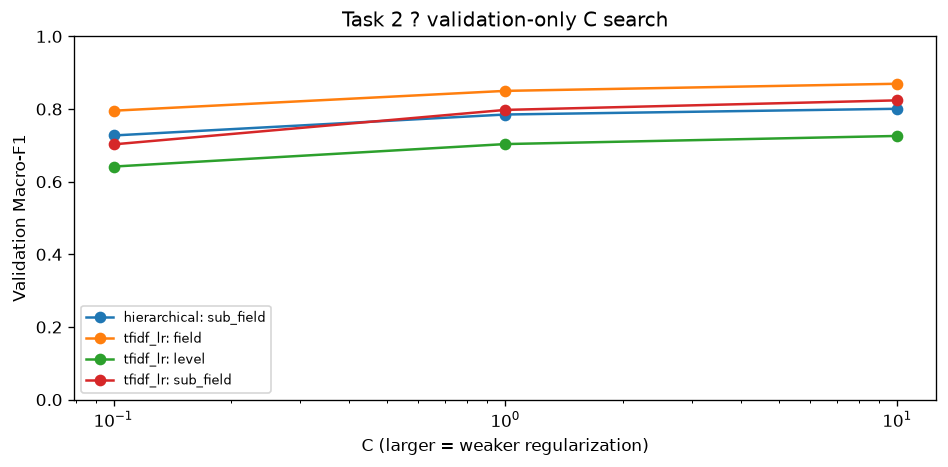

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for (model_name, output), group in tuning.groupby(["model", "output"]):
    ax.plot(group.C, group.value, marker="o", label=f"{model_name}: {output}")
ax.set(xscale="log", xlabel="C (larger = weaker regularization)", ylabel="Validation Macro-F1",
       title="Task 2 - validation-only C search", ylim=(0, 1))
ax.legend(fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 5. Validation and held-out test results

Macro precision/recall/F1 use fixed label sets (7/43/3), with zero division set to zero. Level metrics and three-output exact match exclude Unknown Level rows. Field/Sub-field metrics include all CVs.

Sub-field Top-5 uses descending probability with stable label-order tie breaking, including zero-probability ties. Field is deterministically derived from Sub-field in the dataset, so these are related targets rather than independent annotations.

In [ ]:
display(metrics.loc[metrics.metric.eq("macro_f1")].pivot(
    index=["split", "model"], columns="output", values="value").round(4))

test_summary = metrics.loc[metrics.split.eq("test") & metrics.metric.isin(
    ["accuracy_top1", "accuracy_top5", "exact_match", "field_sub_inconsistency"])]
display(test_summary.pivot(index="model", columns=["output", "metric"], values="value").round(4))
display(metrics.loc[metrics.model.eq(selected_name) & metrics.split.eq("test"),
                    ["output", "metric", "value", "n"]].reset_index(drop=True))

output                field   level  sub_field
split model                                   
test  derived_field  0.8782  0.7243     0.8001
      hierarchical   0.8572  0.7243     0.7715
      majority       0.0654  0.2729     0.0015
      tfidf_lr       0.8572  0.7243     0.8001
val   derived_field  0.8889  0.7260     0.8239
      hierarchical   0.8697  0.7260     0.8008
      majority       0.0661  0.2677     0.0015
      tfidf_lr       0.8697  0.7260     0.8239

output                field     sub_field                       level  \
metric        accuracy_top1 accuracy_top1 accuracy_top5 accuracy_top1   
model                                                                   
derived_field        0.8863        0.8018        0.9621        0.7991   
hierarchical         0.8626        0.7727        0.8617        0.7991   
majority             0.2969        0.0326        0.1304        0.6932   
tfidf_lr             0.8626        0.8018        0.9621        0.7991   

output                all                          
metric        exact_match field_sub_inconsistency  
model                                              
derived_field      0.6556                  0.0000  
hierarchical       0.6291                  0.0000  
majority           0.0000                  1.0000  
tfidf_lr           0.6159                  0.0767

,output,metric,value,n
0,field,accuracy_top1,0.886344,1135
1,field,precision_macro,0.873549,1135
2,field,recall_macro,0.884066,1135
3,field,macro_f1,0.878238,1135
4,sub_field,accuracy_top1,0.801762,1135
5,sub_field,precision_macro,0.811256,1135
6,sub_field,recall_macro,0.801070,1135
7,sub_field,macro_f1,0.800073,1135
8,sub_field,accuracy_top5,0.962115,1135
9,level,accuracy_top1,0.799117,453


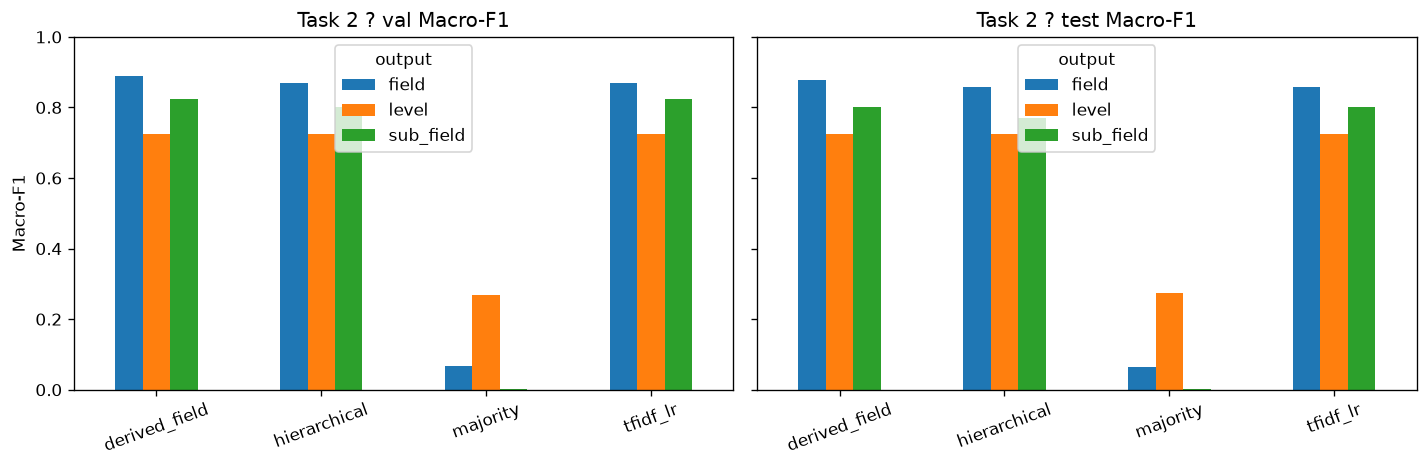

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ("val", "test")):
    rows = metrics.loc[metrics.split.eq(split) & metrics.metric.eq("macro_f1")]
    rows.pivot(index="model", columns="output", values="value").plot.bar(ax=ax)
    ax.set(title=f"Task 2 ? {split} Macro-F1", xlabel="", ylabel="Macro-F1", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
display(fig)
plt.close(fig)

## 6. Confusion matrices and error overview

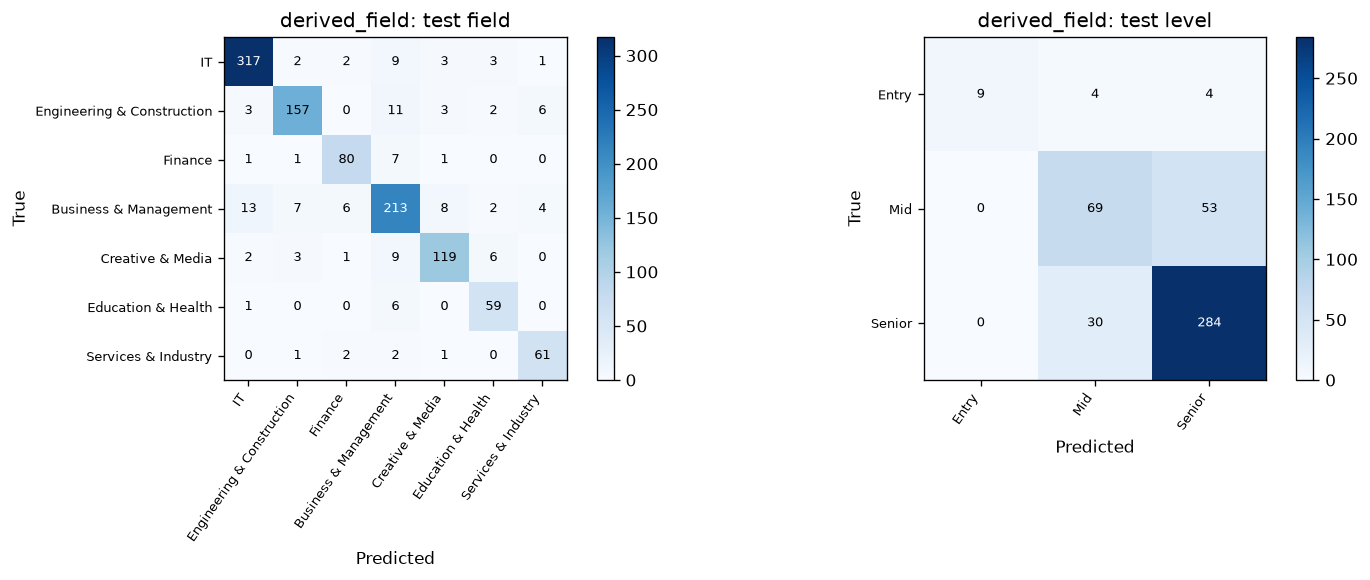

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, output in zip(axes, ("field", "level")):
    table = pd.read_csv(RESULTS / f"task2_confusion_{selected_name}_test_{output}.csv", index_col=0)
    image = ax.imshow(table.to_numpy(), cmap="Blues")
    ax.set(xticks=range(len(table.columns)), yticks=range(len(table.index)),
           xticklabels=table.columns, yticklabels=table.index,
           xlabel="Predicted", ylabel="True", title=f"{selected_name}: test {output}")
    plt.setp(ax.get_xticklabels(), rotation=55, ha="right", fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    for (i, j), value in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, str(value), ha="center", va="center", fontsize=8,
                color="white" if value > table.to_numpy().max()/2 else "black")
    fig.colorbar(image, ax=ax, fraction=0.04)
fig.tight_layout()
display(fig)
plt.close(fig)

In [ ]:
selected_predictions = predictions.loc[predictions.model.eq(selected_name) & predictions.split.eq("test")]
errors = selected_predictions.loc[selected_predictions.sub_field.ne(selected_predictions.pred_sub_field)]
display(errors.groupby(["sub_field", "pred_sub_field"]).size().rename("CVs")
        .sort_values(ascending=False).head(15).reset_index())
known = selected_predictions.level.ne("Unknown")
exact = np.logical_and.reduce([selected_predictions[o].eq(selected_predictions[f"pred_{o}"]).to_numpy()
                               for o in OUTPUT_LABELS])
print(f"Three-output exact match on {known.sum()} known-Level test CVs: {exact[known.to_numpy()].mean():.4f}")
assert all(FIELD_MAP[sub] == field for sub, field in
           zip(selected_predictions.pred_sub_field, selected_predictions.pred_field))

,sub_field,pred_sub_field,CVs
0,Database,SQL Developer,6
1,SQL Developer,Database,4
2,Finance,Accountant,4
3,ETL Developer,SQL Developer,4
4,Accountant,Finance,4
5,Consultant,Information Technology,3
6,Sales,Apparel,3
7,Public Relations,Education,3
8,Data Science,Education,3
9,SQL Developer,ETL Developer,3


Three-output exact match on 453 known-Level test CVs: 0.6556


## 7. Load the saved model and predict new text

In [ ]:
model = load_model(MODELS / selected_name)
examples = [
    "Python developer with 4 years of professional experience in Django SQL and REST APIs.",
    "Accountant with 8 years of professional experience in financial reporting auditing and taxation.",
]
probs = model.predict_proba(examples)
from task2_cls.evaluate import predictions_from_probs
predicted = predictions_from_probs(probs)
display(pd.DataFrame({"example": [1, 2], **predicted}))
for values in probs.values():
    np.testing.assert_allclose(values.sum(axis=1), 1)
print("Saved model loaded successfully.")

,example,field,sub_field,level
0,1,IT,Python Developer,Mid
1,2,Finance,Accountant,Mid


Saved model loaded successfully; no training in this cell.


## 8. Artifacts and remaining experiments

- Models and selection: `models/cls/baselines/`.
- Metrics, tuning, predictions, and confusion tables: `data/results/task2_*`.
- Saved baseline chart: `figures/task2_baseline_comparison.png`.
- Prepared data/metadata: `data/cache/task2*`; fixed IDs: `data/splits/task2.json`.